# 99 - Tổng hợp: chọn model nào?

Gom kết quả của tất cả các notebook trước. **Điểm chất lượng** = trung bình các bài (đã quy về 0-100), bài nào chưa chạy thì bỏ qua. Sau đó lọc theo điều kiện thực tế của board: vừa RAM và trả lời kịp thời gian.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd

In [2]:
base_parts = {"general": ("general_knowledge", "average"), "reasoning": ("reasoning", "gsm8k"),
              "safety": ("safety", "average")}
quant_parts = {"tools": ("tool_calling", "acc_all"), "bfcl": ("bfcl", "overall"),
               "faithful": ("faithfulness", "overall")}

summary = st.load("performance")[["id", "model", "quant", "label", "params_b", "ram_peak_mb", "total_p95_s"]]
for col, (file, metric) in quant_parts.items():          # đo theo từng quant: ghép theo id
    d = st.load(file)
    if metric in d:
        summary = summary.merge(d[["id", metric]].rename(columns={metric: col}), on="id", how="left")
for col, (file, metric) in base_parts.items():           # đo trên model gốc: ghép theo model
    d = st.load_base(file)
    if metric in d:
        summary = summary.merge(d[["model", metric]].rename(columns={metric: col}), on="model", how="left")

score_cols = [c for c in list(base_parts) + list(quant_parts) if c in summary]
summary["quality"] = summary[score_cols].mean(axis=1)
summary["fits"] = (summary.ram_peak_mb <= st.RAM_BUDGET_MB) & (summary.total_p95_s <= st.TTL_S)
summary.sort_values("quality", ascending=False).round(3)

,id,model,quant,label,params_b,ram_peak_mb,total_p95_s,tools,bfcl,faithful,general,reasoning,safety,quality,fits
12,Phi-4-mini-instruct__Q8_0,Phi-4-mini-instruct,Q8_0,Phi-4-mini-instruct (Q8),3.800,4258.4,13.264,0.301,0.829,0.783,0.675,0.83,0.487,0.651,False
14,Phi-4-mini-instruct__Q4_K_M,Phi-4-mini-instruct,Q4_K_M,Phi-4-mini-instruct (Q4),3.800,2728.4,11.196,0.154,0.833,0.867,0.675,0.83,0.487,0.641,False
7,Arch-Agent-3B__F16,Arch-Agent-3B,F16,Arch-Agent-3B (F16),3.000,6054.0,14.217,0.462,0.742,0.750,0.592,0.66,0.494,0.616,False
8,Arch-Agent-1.5B__Q8_0,Arch-Agent-1.5B,Q8_0,Arch-Agent-1.5B (Q8),1.500,1717.2,7.162,0.679,0.783,0.717,0.521,0.54,0.429,0.611,False
11,Arch-Agent-3B__Q8_0,Arch-Agent-3B,Q8_0,Arch-Agent-3B (Q8),3.000,3299.9,12.151,0.442,0.742,0.733,0.592,0.66,0.494,0.610,False
4,Arch-Agent-1.5B__F16,Arch-Agent-1.5B,F16,Arch-Agent-1.5B (F16),1.500,3105.0,8.416,0.679,0.775,0.717,0.521,0.54,0.429,0.610,False
13,Arch-Agent-3B__Q4_K_M,Arch-Agent-3B,Q4_K_M,Arch-Agent-3B (Q4),3.000,2016.3,8.943,0.436,0.662,0.800,0.592,0.66,0.494,0.607,False
9,xLAM-2-1B-fc-r__Q8_0,xLAM-2-1B-fc-r,Q8_0,xLAM-2-1B-fc-r (Q8),1.000,1722.2,7.418,0.532,0.700,0.717,0.572,0.54,0.473,0.589,False
5,xLAM-2-1B-fc-r__F16,xLAM-2-1B-fc-r,F16,xLAM-2-1B-fc-r (F16),1.000,3106.1,8.539,0.494,0.700,0.700,0.572,0.54,0.473,0.580,False
6,Qwen3-1.7B__F16,Qwen3-1.7B,F16,Qwen3-1.7B (F16),1.700,3605.0,8.663,0.154,0.808,0.783,0.519,0.68,0.490,0.573,False


## Biểu đồ 1 - Bảng điểm tổng hợp

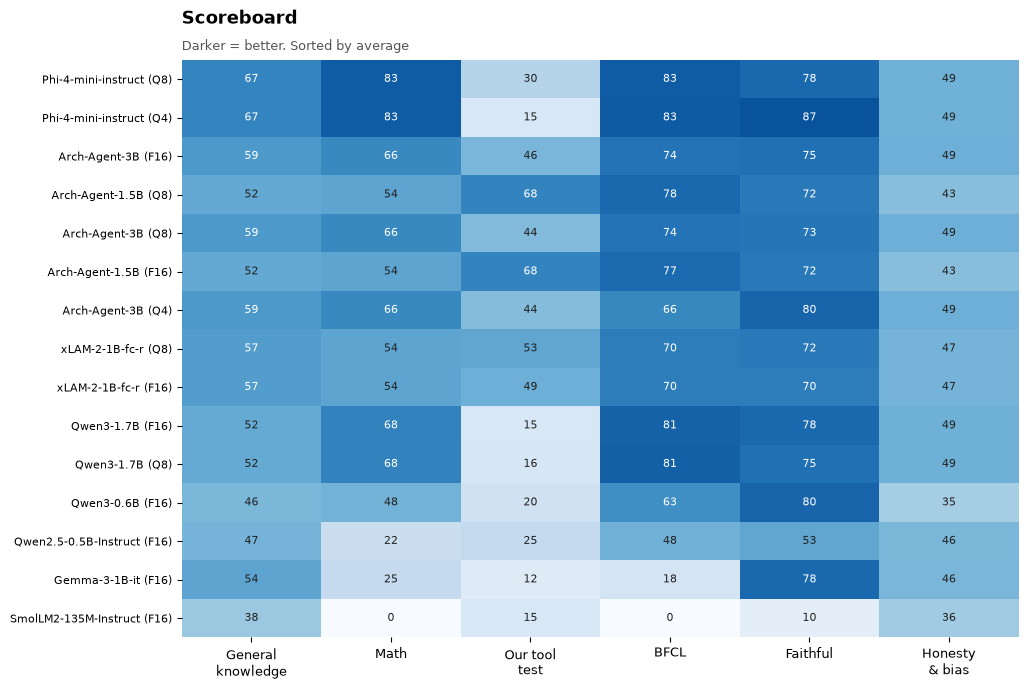

In [3]:
cols = {"general": "General\nknowledge", "reasoning": "Math", "tools": "Our tool\ntest", "bfcl": "BFCL",
        "faithful": "Faithful", "safety": "Honesty\n& bias"}
st.heatmap(summary, {c: t for c, t in cols.items() if c in summary}, "Scoreboard", "Darker = better. Sorted by average",
           name="99_scoreboard")

## Biểu đồ 2 - Chất lượng so với RAM: model nào đáng chọn?

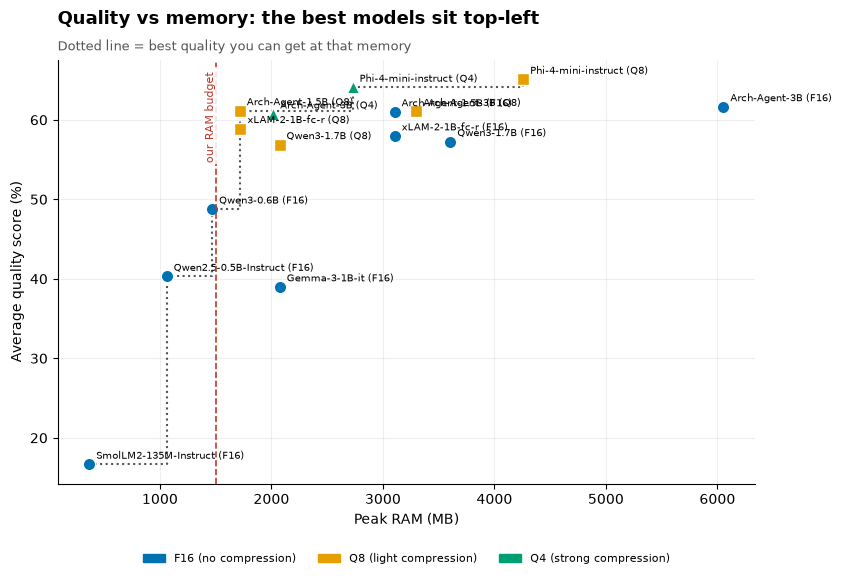

In [4]:
st.scatter_chart(summary, "ram_peak_mb", "quality", "Quality vs memory: the best models sit top-left",
                 "Peak RAM (MB)", "Average quality score (%)", subtitle="Dotted line = best quality you can get at that memory", lines=[(st.RAM_BUDGET_MB, "our RAM budget")],
                 frontier=True, name="99_quality_vs_ram")

## Biểu đồ 3 - Model lớn đã nén có hơn model nhỏ không nén không?

Trục ngang là kích thước model (số tỉ tham số). Nếu các chấm cam/xanh lá (đã nén) ở bên phải nằm CAO hơn các chấm xanh dương (không nén) ở bên trái thì nén model lớn là đáng.

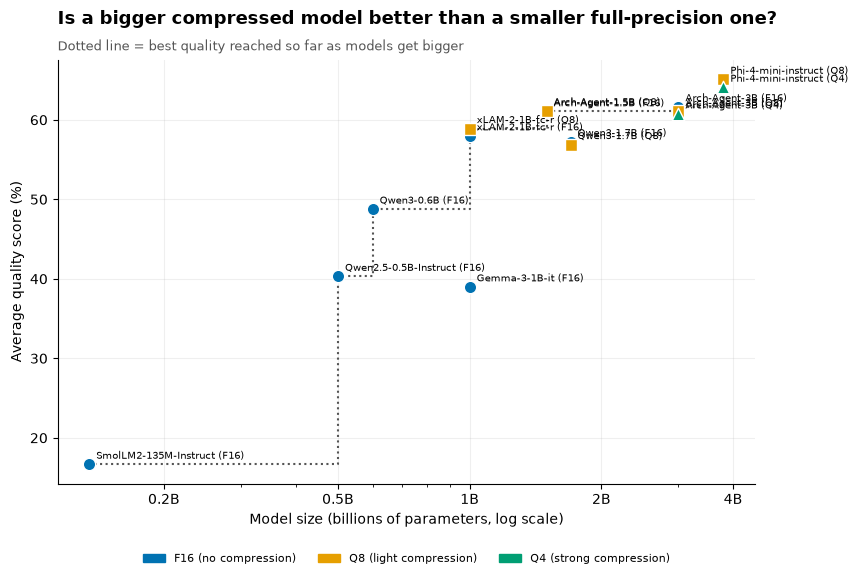

In [5]:
st.scatter_chart(summary, "params_b", "quality", "Is a bigger compressed model better than a smaller full-precision one?",
                 "Model size (billions of parameters, log scale)", "Average quality score (%)", logx=True,
                 subtitle="Dotted line = best quality reached so far as models get bigger",
                 frontier=True, name="99_size_vs_quality")

### Bảng trả lời trực tiếp: với mỗi model lớn đã nén, so với model nhỏ hơn không nén tốt nhất

In [6]:
full = summary[summary.quant == "F16"]
rows = []
for r in summary[summary.quant != "F16"].itertuples():
    smaller = full[full.params_b < r.params_b].dropna(subset=["quality"])
    if len(smaller) and r.quality == r.quality:
        best = smaller.sort_values("quality").iloc[-1]
        rows.append({"compressed bigger model": r.label, "its quality": round(r.quality * 100, 1),
                     "best smaller uncompressed model": best.label, "its quality ": round(best.quality * 100, 1),
                     "bigger compressed wins?": "YES" if r.quality > best.quality else "no"})
pd.DataFrame(rows)

,compressed bigger model,its quality,best smaller uncompressed model,its quality,bigger compressed wins?
0,Arch-Agent-1.5B (Q8),61.1,xLAM-2-1B-fc-r (F16),58.0,YES
1,xLAM-2-1B-fc-r (Q8),58.9,Qwen3-0.6B (F16),48.8,YES
2,Qwen3-1.7B (Q8),56.9,Arch-Agent-1.5B (F16),61.0,no
3,Arch-Agent-3B (Q8),61.0,Arch-Agent-1.5B (F16),61.0,YES
4,Phi-4-mini-instruct (Q8),65.1,Arch-Agent-3B (F16),61.6,YES
5,Arch-Agent-3B (Q4),60.7,Arch-Agent-1.5B (F16),61.0,no
6,Phi-4-mini-instruct (Q4),64.1,Arch-Agent-3B (F16),61.6,YES


Nhớ: số RAM và thời gian chỉ chính thức khi đo trên UNO Q. Nếu danh sách trên rỗng, nới `st.RAM_BUDGET_MB` hoặc xem model nhỏ nhất có đạt chất lượng tối thiểu không.